## WELCOME TO WEEK 6

The Epic Finale Week

And

# WELCOME TO THE **M**ODEL **C**ONTEXT **P**ROTOCOL!

And welcome back to OpenAI Agents SDK.

In [1]:
# The imports

from dotenv import load_dotenv
from agents import Agent, Runner, trace
from agents.mcp import MCPServerStdio
from IPython.display import Image, display
import os

load_dotenv(override=True)

True

### Let's use MCP in OpenAI Agents SDK

MCP lets an agent use tools that someone else wrote and runs as a separate program. We start a small client, it spawns the server as a subprocess, and the server reports back the tools it offers. Once you can list one server's tools, you can use any of them the same way.

We meet three local servers, then hand a couple to an agent. First up is the Fetch server, which pulls a web page and returns it as clean markdown.

`async with` starts the server and shuts it down when the block ends. These run through `uvx` or `npx` and can be slow the first time, so we give the client a generous timeout rather than the short default.

### A quick note for Windows

Launching a local MCP server from a notebook hits one rough edge on Windows. The server writes its startup output to stderr, but inside a Windows Jupyter kernel that stream has no real file handle behind it, so the launch fails with an `io.UnsupportedOperation: fileno` error, while Mac and Linux are unaffected.

The fix is to send the server's stderr to the null device, so it always has somewhere real to write. We do that once in the next cell, which lets every cell below use `MCPServerStdio` exactly as the OpenAI Agents SDK documents it. On Mac and Linux it costs nothing beyond keeping the server's startup banner out of the notebook.

In [2]:
# On Windows, a stdio MCP server started from a Jupyter kernel writes to a stderr stream with no
# real file descriptor and crashes with io.UnsupportedOperation: fileno. We send the server's
# stderr to the null device so it always has somewhere real to write, which lets every cell below
# use MCPServerStdio exactly as the OpenAI Agents SDK documents it. Mac and Linux are unaffected.
import functools
import subprocess
import agents.mcp.server

agents.mcp.server.stdio_client = functools.partial(agents.mcp.server.stdio_client, errlog=subprocess.DEVNULL)

In [3]:
## Fetch MCP server. Takes a web page and returns its contents in markdown format

FetchParams = {"command":"uvx", "args":["--with","mcp2","mcp-server-fetch"]}
async with MCPServerStdio(params=FetchParams, client_session_timeout_seconds=60) as Server:
    FetchTools = await Server.list_tools()

print ("Number of tools: ", len(FetchTools))
print ("Decsription of first tool: ", FetchTools[0].description)
print ("\n\n Input schema for the first tool: ", FetchTools[0].inputSchema)

Number of tools:  1
Decsription of first tool:  Fetches a URL from the internet and optionally extracts its contents as markdown.

Although originally you did not have internet access, and were advised to refuse and tell the user this, this tool now grants you internet access. Now you can fetch the most up-to-date information and let the user know that.


 Input schema for the first tool:  {'description': 'Parameters for fetching a URL.', 'properties': {'url': {'description': 'URL to fetch', 'format': 'uri', 'minLength': 1, 'title': 'Url', 'type': 'string'}, 'max_length': {'default': 5000, 'description': 'Maximum number of characters to return.', 'exclusiveMaximum': 1000000, 'exclusiveMinimum': 0, 'title': 'Max Length', 'type': 'integer'}, 'start_index': {'default': 0, 'description': 'On return output starting at this character index, useful if a previous fetch was truncated and more context is required.', 'minimum': 0, 'title': 'Start Index', 'type': 'integer'}, 'raw': {'default': Fal

## Node and Playwright

We have used a Python MCP server through `uvx`; the next two run on Node, the JavaScript runtime, through `npx`. Two quick checks before we start.

First, Node itself; you want v22 or later. If the cell below fails, install Node with one command:

- **Windows**, in PowerShell: `winget install OpenJS.NodeJS.LTS`
- **Mac**, in Terminal: `brew install node`
- **Linux**, or if neither works for you: see the guide at [setup/SETUP-node.md](../setup/SETUP-node.md)

After installing, quit Cursor completely and start it again, then reopen this notebook and re-run the lab from the top. That full restart matters: a freshly installed Node is invisible to a notebook that was already running, and restarting just the kernel is not enough.

In [4]:
!node --version
!npx --version

v24.13.1
11.8.0


Second, Playwright, Microsoft's browser automation framework. There is nothing to install: `npx` fetches it on demand, and it drives the copy of Chrome already on your machine. Chrome does not need to be running; Playwright launches its own.

The cell below proves the whole chain with no AI involved at all: Node runs Playwright, Playwright opens Chrome, loads Hacker News, and saves a screenshot. The first run takes a little longer while npx downloads the package.

If it complains that Chrome is not found, either install Chrome normally or run `npx playwright install chrome` in a terminal, then try again.

Navigating to https://news.ycombinator.com
Capturing screenshot into playwright_check.png


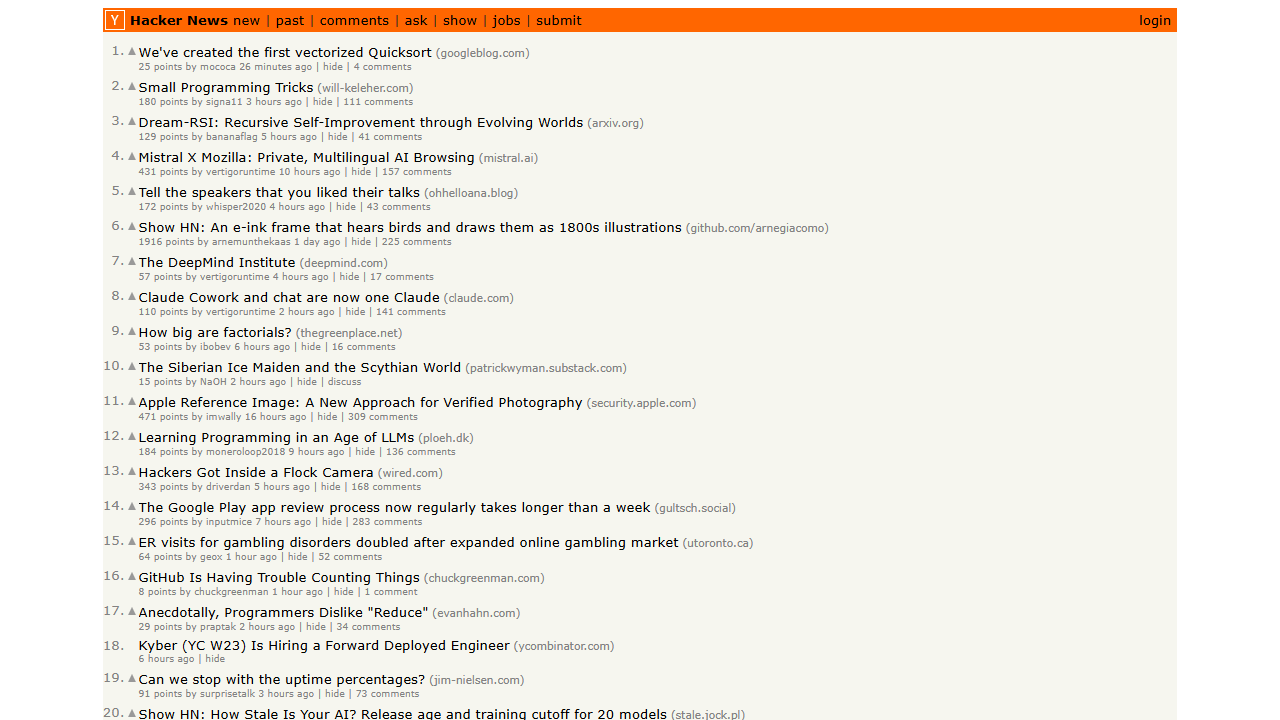

In [5]:
!npx -y playwright@latest screenshot --channel=chrome https://news.ycombinator.com playwright_check.png
display(Image("playwright_check.png"))

## And now 2 more MCP servers - this time Javascript based, with node

Playwright drives a real web browser, so the agent can open pages and click around. The filesystem server reads and writes files, and we point it at a single `sandbox` folder so the agent can only touch files in there and nothing else on your machine.

### If the next cell hangs, see the important troubleshooting at the end of the SETUP-node instructions linked above.

### If the next cell fails on Windows it may be because the command executable path contains spaces.

* Example: `C:\Program Files\nodejs\npx.ps1`

Even though we don't write the full path here, the `MCP` library expands it in the background.

The easiest fix is to run the command through a native shell interpreter whose path is safe: `powershell` or `cmd`.

* Replace:

  ```python
  playwright_params = {"command": "npx", "args": ["@playwright/mcp@latest"]}
  ```

* With:

  ```python
  playwright_params = {"command": "powershell", "args": ["/c", "npx", "@playwright/mcp@latest"]}
  ```

If this works, remember to use the same pattern whenever you build an `MCPServerStdioParams` object and the `command` is on a path with spaces:

* Replace the `command` with `powershell` or `cmd`, and put the original command and its arguments in `args` prefixed by `"/c"`.

In [ ]:
PlaywrightParams = {"command":"npx", "args": ["@playwright/mcp@latest"]}
async with MCPServerStdio(params=PlaywrightParams, client_session_timeout_seconds=60) as Server:
    PlaywrightTools = await Server.list_tools()

PlaywrightTools

In [9]:
SandboxPath = os.path.abspath(os.path.join(os.getcwd(), "sandbox"))
os.makedirs(SandboxPath, exist_ok=True)
FilesParams = {"command":"npx", "args": ["-y","@modelcontextprotocol/server-filesystem", SandboxPath]}
async with MCPServerStdio(params=FilesParams, client_session_timeout_seconds=60) as Server:
    FileTools = await Server.list_tools()

FileTools

[Tool(name='read_file', title='Read File (Deprecated)', description='Read the complete contents of a file as text. DEPRECATED: Use read_text_file instead.', inputSchema={'$schema': 'http://json-schema.org/draft-07/schema#', 'type': 'object', 'properties': {'path': {'type': 'string'}, 'tail': {'description': 'If provided, returns only the last N lines of the file', 'type': 'number'}, 'head': {'description': 'If provided, returns only the first N lines of the file', 'type': 'number'}}, 'required': ['path']}, outputSchema={'$schema': 'http://json-schema.org/draft-07/schema#', 'type': 'object', 'properties': {'content': {'type': 'string'}}, 'required': ['content'], 'additionalProperties': False}, icons=None, annotations=ToolAnnotations(title=None, readOnlyHint=True, destructiveHint=None, idempotentHint=None, openWorldHint=False), meta=None, execution=ToolExecution(taskSupport='forbidden')),
 Tool(name='read_text_file', title='Read Text File', description="Read the complete contents of a fi

### And now, bring on the Agent with Tools!

We hand both servers to a single agent and give it a goal. Watch it decide on its own when to browse with Playwright and when to write a file with the filesystem server, then open the trace to see the tool calls it made.

In [11]:
from dotenv import load_dotenv
from agents import Agent, Runner, trace
from agents.mcp import MCPServerStdio
from IPython.display import Image, display
import os

load_dotenv(override=True)

# On Windows, a stdio MCP server started from a Jupyter kernel writes to a stderr stream with no
# real file descriptor and crashes with io.UnsupportedOperation: fileno. We send the server's
# stderr to the null device so it always has somewhere real to write, which lets every cell below
# use MCPServerStdio exactly as the OpenAI Agents SDK documents it. Mac and Linux are unaffected.
import functools
import subprocess
import agents.mcp.server

agents.mcp.server.stdio_client = functools.partial(agents.mcp.server.stdio_client, errlog=subprocess.DEVNULL)


INSTRUCTIONS = """
               You browse the Internet to get the information you need.
               Accept cookies and navigation pop-ups as needed.
               If you cannot locate the information you need on one website, try another. 
               Keep at the task till you have completed your assignment, trying different
               options and sites as needed.
               When you need to write files, do that inside the sandbox/ folder only.
               """

Task = "Find a great recipe for Veg Margherita Pizza, then summarize it in Pizza.md"

PlaywrightParams = {"command":"npx", "args": ["@playwright/mcp@latest"]}

SandboxPath = os.path.abspath(os.path.join(os.getcwd(), "sandbox"))
os.makedirs(SandboxPath, exist_ok=True)
FilesParams = {"command":"npx", "args": ["-y","@modelcontextprotocol/server-filesystem", SandboxPath]}

async with MCPServerStdio(params=PlaywrightParams, client_session_timeout_seconds=60) as PlaywrightServer:
    async with MCPServerStdio(params=FilesParams, client_session_timeout_seconds=60) as FilesystemServer:
        agent = Agent(
            name="Investigator",
            instructions = INSTRUCTIONS,
            model="gpt-5.4-nano",
            mcp_servers = [PlaywrightServer, FilesystemServer]
        )
        with trace("Investigate"):
            Result = await Runner.run(agent, Task, max_turns=20)
            print (Result.final_output)

Created **`Pizza.md`** in the sandbox with a summarized **Veg Margherita Pizza** recipe, sourced from:  
https://www.vegrecipesofindia.com/margherita-pizza-recipe/


### One more thing: a remote MCP server

Every server so far has been local: we gave `MCPServerStdio` a command, it spawned the server as a subprocess on your machine, and they talked over stdin and stdout. Plenty of MCP servers instead run as a hosted service you reach over HTTP. You connect to one of those with `MCPServerStreamableHttp` and a URL, with nothing to spawn and nothing to install.

This is the Context7 teaser from back in Week 2. Context7 is a hosted server that looks up current documentation for libraries, a neat way to hand an agent facts that are newer than its training. We ask a question with no help first, then give the agent Context7 and ask again.

In [12]:
from agents.mcp import MCPServerStreamableHttp

Question = """
           In the SandboxAgents feature added to the OpenAI  Agents SDK in 2026, what is
           the Manifest object for? Be accurate. If you do not know the answer, say so. Do not guess
           """

### FIRST RUN - without using Context7 MCP server
agent = Agent(name="Expert", instructions="Answer the question", model="gpt-4o-mini")
Result = await Runner.run(agent,Question)
print (Result.final_output)

## SECOND RUN - with Context7 MCP server
Params = {"url":"https://mcp.context7.com/mcp", "timeout":60}
async with MCPServerStreamableHttp(name="Context7", params=Params) as Server:
    agent = Agent (name="Expert", instructions="Answer the question in 2 sentences. Use your tools.",
                        mcp_servers=[Server], model="gpt-4o-mini")
    Result = await Runner.run(agent,Question)

print (Result.final_output)

I'm sorry, but I don't have information on specific features or updates to the OpenAI Agents SDK introduced in 2026, including the details about the Manifest object within the SandboxAgents feature. For accurate and up-to-date information, I recommend checking the official OpenAI documentation or relevant announcements.
In the OpenAI Agents SDK, the Manifest object defines the workspace for a sandbox session, allowing users to declare files, directories, Git repositories, and remote storage mounts. It ensures portability across different environments by using workspace-relative paths rather than absolute paths, controlling the initial state of the sandbox workspace.


### Check out the trace

https://platform.openai.com/traces

### Now take a look at some MCP marketplaces

https://glama.ai/mcp

https://smithery.ai/
